In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
txn_users = pd.read_excel("/content/phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx",
                          sheet_name= 'State_Txn and Users')

txn_split = pd.read_excel("/content/phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx",
                          sheet_name= 'State_TxnSplit')

device_data = pd.read_excel("/content/phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx",
                          sheet_name= 'State_DeviceData')

District_users = pd.read_excel("/content/phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx",
                          sheet_name= 'District_Txn and Users')


District_demo = pd.read_excel("/content/phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx",
                          sheet_name= 'District Demographics')


Admin = pd.read_excel("/content/phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx",
                          sheet_name= 'Admin')

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


In [4]:
#Data Loading and Undeerstanding

In [5]:
txn_users.head(5)

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,2.833854e+07,2498.989022,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,5.555747e+07,3415.768284,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,9.054834e+07,3811.277720,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,1.022997e+08,3355.630147,18596,0


In [6]:
txn_split.tail(10)

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
2504,West Bengal,2021,1,Peer-to-peer payments,53869075,2.022402e+11,3754.292226
2505,West Bengal,2021,1,Merchant payments,37143701,2.891834e+10,778.553104
2506,West Bengal,2021,1,Recharge & bill payments,26673733,1.133967e+10,425.124820
2507,West Bengal,2021,1,Financial Services,166727,1.754458e+08,1052.293941
2508,West Bengal,2021,1,Others,400816,2.635025e+08,657.415236
2509,West Bengal,2021,2,Peer-to-peer payments,64661051,2.308123e+11,3569.572026
2510,West Bengal,2021,2,Merchant payments,41696787,3.478787e+10,834.305703
2511,West Bengal,2021,2,Recharge & bill payments,34799709,1.333145e+10,383.090958
2512,West Bengal,2021,2,Financial Services,190537,1.864665e+08,978.636630
2513,West Bengal,2021,2,Others,549353,3.167447e+08,576.577748


In [7]:
device_data.shape

(5544, 6)

In [8]:
print(len(device_data)//2)

2772


In [9]:
#10 rows from middle of data
device_data[2772:2782]

,State,Year,Quarter,Brand,Registered Users,Percentage
2772,Lakshadweep,2018,1,Samsung,102,0.203593
2773,Lakshadweep,2018,1,Xiaomi,100,0.199601
2774,Lakshadweep,2018,1,Vivo,67,0.133733
2775,Lakshadweep,2018,1,Oppo,56,0.111776
2776,Lakshadweep,2018,1,Huawei,25,0.049900
2777,Lakshadweep,2018,1,OnePlus,22,0.043912
2778,Lakshadweep,2018,1,Apple,20,0.039920
2779,Lakshadweep,2018,1,Realme,20,0.039920
2780,Lakshadweep,2018,1,Gionee,12,0.023952
2781,Lakshadweep,2018,1,COOLPAD,10,0.019960


In [10]:
District_users.head(10)

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1.139849e+06,2158.804548,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,9.316631e+05,2107.835016,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3.072437e+06,2743.247239,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1.317863e+06,1597.409798,911,0
5,Andaman & Nicobar Islands,2018,2,South Andaman,AN03,9395,2.394824e+07,2549.040502,8143,0
6,Andaman & Nicobar Islands,2018,3,Nicobars,AN01,1471,6.387829e+06,4342.507921,467,0
7,Andaman & Nicobar Islands,2018,3,North And Middle Andaman,AN02,1283,4.901530e+06,3820.365954,1208,0
8,Andaman & Nicobar Islands,2018,3,South Andaman,AN03,13511,4.426811e+07,3276.449742,10474,0
9,Andaman & Nicobar Islands,2018,4,Nicobars,AN01,1485,7.180859e+06,4835.595525,536,0


In [11]:
District_users.tail(10)

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
10238,West Bengal,2021,2,Murshidabad,WB14,8602251,1.999694e+10,2324.616616,1248602,16530655
10239,West Bengal,2021,2,Nadia,WB15,5524174,1.122758e+10,2032.445525,955428,13665885
10240,West Bengal,2021,2,North Twenty Four Parganas,WB16,17258291,3.041482e+10,1762.331031,2660664,37899453
10241,West Bengal,2021,2,Paschim Bardhaman,WB17,4893774,8.731263e+09,1784.157359,789026,10545670
10242,West Bengal,2021,2,Paschim Medinipur,WB18,5051834,1.030351e+10,2039.558976,856640,16201033
10243,West Bengal,2021,2,Purba Bardhaman,WB19,3920729,7.572502e+09,1931.401639,787970,12128849
10244,West Bengal,2021,2,Purba Medinipur,WB20,6418522,1.515507e+10,2361.146027,946277,15491958
10245,West Bengal,2021,2,Purulia,WB21,1895981,2.790996e+09,1472.059252,435131,8843358
10246,West Bengal,2021,2,South Twenty Four Parganas,WB22,6661813,1.339853e+10,2011.243709,1286588,19344293
10247,West Bengal,2021,2,Uttar Dinajpur,WB23,2253385,5.564221e+09,2469.272118,392388,8184990


In [12]:
#display every 10th row
District_demo[0::10]

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0,213,AP01,Anantapur
10,Andhra Pradesh,Visakhapatnam,Visakhapatnam,4288113,11161.0,384,AP10,Visakhapatnam
20,Arunachal Pradesh,Lepa Rada,Basar,0,0.0,0,AR08,Lepa Rada
30,Arunachal Pradesh,Siang,Pangin,31920,2919.0,11,AR18,Siang
40,Assam,Barpeta,Barpeta,1693622,3245.0,520,AS03,Barpeta
...,...,...,...,...,...,...,...,...
700,Chandigarh,Chandigarh,Chandigarh,1055450,114.0,9258,CH01,Chandigarh
710,Jammu & Kashmir,Jammu,Jammu,1526406,3097.0,596,JK07,Jammu
720,Jammu & Kashmir,Samba,Samba,318611,913.0,318,JK17,Samba
730,Delhi,North Delhi,Sadar Bazaar,887978,59.0,14557,DL04,North


In [13]:
txn_users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   State             504 non-null    object 
 1   Year              504 non-null    int64  
 2   Quarter           504 non-null    int64  
 3   Transactions      504 non-null    int64  
 4   Amount (INR)      503 non-null    float64
 5   ATV (INR)         504 non-null    float64
 6   Registered Users  504 non-null    int64  
 7   App Opens         504 non-null    int64  
dtypes: float64(2), int64(5), object(1)
memory usage: 31.6+ KB


In [14]:
txn_split.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2514 entries, 0 to 2513
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   State             2514 non-null   object 
 1   Year              2514 non-null   int64  
 2   Quarter           2514 non-null   int64  
 3   Transaction Type  2514 non-null   object 
 4   Transactions      2514 non-null   int64  
 5   Amount (INR)      2514 non-null   float64
 6   ATV (INR)         2514 non-null   float64
dtypes: float64(2), int64(3), object(2)
memory usage: 137.6+ KB


In [15]:
device_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5544 entries, 0 to 5543
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   State             5544 non-null   object 
 1   Year              5544 non-null   int64  
 2   Quarter           5544 non-null   int64  
 3   Brand             5544 non-null   object 
 4   Registered Users  5544 non-null   int64  
 5   Percentage        5544 non-null   float64
dtypes: float64(1), int64(3), object(2)
memory usage: 260.0+ KB


In [16]:
District_users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10248 entries, 0 to 10247
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   State             10248 non-null  object 
 1   Year              10248 non-null  int64  
 2   Quarter           10248 non-null  int64  
 3   District          10248 non-null  object 
 4   Code              10220 non-null  object 
 5   Transactions      10248 non-null  int64  
 6   Amount (INR)      10248 non-null  float64
 7   ATV (INR)         10244 non-null  float64
 8   Registered Users  10248 non-null  int64  
 9   App Opens         10248 non-null  int64  
dtypes: float64(2), int64(5), object(3)
memory usage: 800.8+ KB


In [17]:
District_demo.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 742 entries, 0 to 741
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   State           742 non-null    object 
 1   District        742 non-null    object 
 2   Headquarters    742 non-null    object 
 3   Population      742 non-null    int64  
 4   Area (sq km)    742 non-null    float64
 5   Density         742 non-null    int64  
 6   Code            742 non-null    object 
 7   Alternate Name  742 non-null    object 
dtypes: float64(1), int64(2), object(5)
memory usage: 46.5+ KB


In [18]:
#lets check the statistics suammary of each dataset


txn_users.describe()

,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
count,504.000000,504.000000,5.040000e+02,5.030000e+02,504.000000,5.040000e+02,5.040000e+02
mean,2019.285714,2.357143,4.074000e+07,7.083332e+10,1993.471543,4.777501e+06,9.774471e+07
std,1.031181,1.109971,8.228714e+07,1.440902e+11,607.464894,6.644496e+06,2.042376e+08
min,2018.000000,1.000000,7.780000e+02,1.928611e+06,0.000000,5.010000e+02,0.000000e+00
25%,2018.000000,1.000000,5.925578e+05,1.167157e+09,1598.910667,1.574202e+05,0.000000e+00
50%,2019.000000,2.000000,6.217487e+06,1.051605e+10,1861.380589,1.747914e+06,2.930574e+06
75%,2020.000000,3.000000,4.363675e+07,6.947045e+10,2259.087924,7.320945e+06,8.615022e+07
max,2021.000000,4.000000,5.736165e+08,1.027958e+12,3938.733850,3.966470e+07,1.208084e+09


In [19]:
txn_split.describe()

,Year,Quarter,Transactions,Amount (INR),ATV (INR)
count,2514.000000,2514.000000,2.514000e+03,2.514000e+03,2514.000000
mean,2019.286794,2.358393,8.167446e+06,1.443978e+10,1349.927929
std,1.030807,1.109251,2.423645e+07,5.995054e+10,1534.866221
min,2018.000000,1.000000,2.000000e+00,3.439721e+01,17.198606
25%,2018.000000,1.000000,2.788075e+04,1.762412e+07,385.735827
50%,2019.000000,2.000000,2.687980e+05,1.901189e+08,720.940406
75%,2020.000000,3.000000,3.683230e+06,2.661248e+09,1352.790116
max,2021.000000,4.000000,2.795990e+08,8.721520e+11,7767.539936


In [20]:
device_data.describe()

,Year,Quarter,Registered Users,Percentage
count,5544.000000,5544.000000,5.544000e+03,5544.000000
mean,2019.285714,2.357143,4.343183e+05,0.090909
std,1.030250,1.108970,9.056069e+05,0.083095
min,2018.000000,1.000000,1.000000e+01,0.006373
25%,2018.000000,1.000000,8.055750e+03,0.021588
50%,2019.000000,2.000000,7.442250e+04,0.056914
75%,2020.000000,3.000000,3.978875e+05,0.143626
max,2021.000000,4.000000,9.764252e+06,0.478367


In [21]:
District_users.describe()

,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
count,10248.000000,10248.000000,1.024800e+04,1.024800e+04,10244.000000,1.024800e+04,1.024800e+04
mean,2019.285714,2.357143,2.003607e+06,3.542311e+09,1909.796545,2.349591e+05,4.807117e+06
std,1.030208,1.108924,9.613466e+06,1.473154e+10,600.943349,4.605978e+05,1.562541e+07
min,2018.000000,1.000000,0.000000e+00,0.000000e+00,84.944283,2.200000e+01,0.000000e+00
25%,2018.000000,1.000000,1.031418e+05,1.756668e+08,1554.589051,3.619550e+04,0.000000e+00
50%,2019.000000,2.000000,3.763065e+05,6.784562e+08,1863.135530,1.067640e+05,6.403025e+05
75%,2020.000000,3.000000,1.272815e+06,2.377256e+09,2203.083552,2.573165e+05,4.346320e+06
max,2021.000000,4.000000,3.487128e+08,4.444224e+11,11209.980550,1.060461e+07,5.544197e+08


In [22]:
District_demo.describe()

,Population,Area (sq km),Density
count,7.420000e+02,742.000000,742.000000
mean,1.668555e+06,4395.373120,838.512129
std,1.458849e+06,4254.676124,2754.406896
min,0.000000e+00,0.000000,0.000000
25%,6.530815e+05,2039.750000,198.000000
50%,1.322359e+06,3402.500000,353.000000
75%,2.297440e+06,5432.750000,686.250000
max,1.008285e+07,45652.000000,36155.000000


In [23]:
#Null values


txn_users.isnull().sum()

,0
State,0
Year,0
Quarter,0
Transactions,0
Amount (INR),1
ATV (INR),0
Registered Users,0
App Opens,0


In [24]:
txn_split.isnull().sum()

,0
State,0
Year,0
Quarter,0
Transaction Type,0
Transactions,0
Amount (INR),0
ATV (INR),0


In [25]:
device_data.isnull().sum()

,0
State,0
Year,0
Quarter,0
Brand,0
Registered Users,0
Percentage,0


In [26]:
District_users.isnull().sum()

,0
State,0
Year,0
Quarter,0
District,0
Code,28
Transactions,0
Amount (INR),0
ATV (INR),4
Registered Users,0
App Opens,0


In [27]:
#percentage of null in Code
District_users['Code'].isnull().sum()/District_users.isnull().sum().sum()*100

np.float64(87.5)

In [28]:
#percentage of null in ATV(INR)
District_users['ATV (INR)'].isnull().sum()/District_users.isnull().sum().sum()*100

np.float64(12.5)

In [29]:
District_demo.isnull().sum()

,0
State,0
District,0
Headquarters,0
Population,0
Area (sq km),0
Density,0
Code,0
Alternate Name,0


In [30]:
# Total number of states


District_users['State'].nunique()

36

In [31]:
# total number of districts

In [32]:

District_users['District'].nunique()

723

In [33]:
#State with number of district, uttar pradesh is the state with max districts.

District_users.groupby('State')['District'].nunique().sort_values(ascending=False).reset_index()

,State,District
0,Uttar Pradesh,75
1,Madhya Pradesh,52
2,Bihar,38
3,Tamil Nadu,37
4,Maharashtra,36
5,Telangana,33
6,Gujarat,33
7,Assam,33
8,Rajasthan,33
9,Odisha,30


In [34]:
#Task 2: Exploratory Data Analysis (EDA)

In [35]:
"""
1. Calculate the total number of transactions and total transaction amount for
each state over the years. Display the results in a tabular format.

2. Identify the top 5 states with the highest transaction volumes and the top 5
states with the lowest transaction volumes. Display the results.
"""

'\n1. Calculate the total number of transactions and total transaction amount for\neach state over the years. Display the results in a tabular format.\n\n2. Identify the top 5 states with the highest transaction volumes and the top 5\nstates with the lowest transaction volumes. Display the results.\n'

In [36]:
#total number of transaction transaction

txn_users['Transactions'].count()

np.int64(504)

In [37]:
#total transaction amount for each States over the Years
txn_users.groupby(['State', 'Year'])['Amount (INR)'].sum()

State                      Year
Andaman & Nicobar Islands  2018    1.890761e+08
                           2019    4.734648e+08
                           2020    1.296423e+09
                           2021    1.682854e+09
Andhra Pradesh             2018    1.220720e+11
                                       ...     
Uttarakhand                2021    7.727901e+10
West Bengal                2018    1.115887e+11
                           2019    2.660145e+11
                           2020    5.527316e+11
                           2021    5.223720e+11
Name: Amount (INR), Length: 144, dtype: float64

In [38]:
# State with highest trasaction volume

top5 = txn_users.groupby('State')['Transactions'].sum().sort_values(ascending=False).head(5)

top5

,Transactions
State,
Karnataka,2981044533
Maharashtra,2833670154
Telangana,2347430243
Andhra Pradesh,1781091169
Rajasthan,1382918930


In [39]:
# State with highest trasaction volume

lowest5 = txn_users.groupby('State')['Transactions'].sum().sort_values(ascending=True).head(5)

lowest5

,Transactions
State,
Lakshadweep,71610
Andaman & Nicobar Islands,1223565
Ladakh,1880109
Mizoram,2162776
Meghalaya,5648913


In [40]:
txn_split.head(2)

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1.845307e+06,439.358921
1,Andaman & Nicobar Islands,2018,1,Peer-to-peer payments,1871,1.213866e+07,6487.790112


In [41]:
#2.2 Identify the most common transaction types in each state and quarter
pivot = txn_split.pivot_table(index=['State', 'Quarter'], columns = 'Transaction Type',
                      values='Transactions', aggfunc='count').reset_index()

pivot.head(10)

Transaction Type,State,Quarter,Financial Services,Merchant payments,Others,Peer-to-peer payments,Recharge & bill payments
0,Andaman & Nicobar Islands,1,4,4,4,4,4
1,Andaman & Nicobar Islands,2,4,4,4,4,4
2,Andaman & Nicobar Islands,3,3,3,3,3,3
3,Andaman & Nicobar Islands,4,3,3,3,3,3
4,Andhra Pradesh,1,4,4,4,4,4
5,Andhra Pradesh,2,4,4,4,4,4
6,Andhra Pradesh,3,3,3,3,3,3
7,Andhra Pradesh,4,3,3,3,3,3
8,Arunachal Pradesh,1,4,4,4,4,4
9,Arunachal Pradesh,2,4,4,4,4,4


In [42]:
# 2.3: Determine the device brand with the highest number of registered users in each state
merger = device_data.merge(txn_users, on=['State','Year','Quarter'])

merger.head()




,State,Year,Quarter,Brand,Registered Users_x,Percentage,Transactions,Amount (INR),ATV (INR),Registered Users_y,App Opens
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.247033,6658,1.463176e+07,2197.621091,6740,0
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.214392,6658,1.463176e+07,2197.621091,6740,0
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.145697,6658,1.463176e+07,2197.621091,6740,0
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.074332,6658,1.463176e+07,2197.621091,6740,0
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.049258,6658,1.463176e+07,2197.621091,6740,0


In [43]:
#Determine the device brand with the highest number of registered users in each state

brand_users = merger.groupby(['State', 'Brand'])['Registered Users_x'].sum().reset_index()

brand_users.loc[
    brand_users.groupby('State')['Registered Users_x'].idxmax()
].reset_index(drop=True)

,State,Brand,Registered Users_x
0,Andaman & Nicobar Islands,Xiaomi,97889
1,Andhra Pradesh,Xiaomi,40061549
2,Arunachal Pradesh,Xiaomi,437803
3,Assam,Xiaomi,6979357
4,Bihar,Xiaomi,33721314
5,Chandigarh,Xiaomi,896628
6,Chhattisgarh,Xiaomi,8763373
7,Dadra & Nagar Haveli and Daman & Diu,Xiaomi,638834
8,Delhi,Xiaomi,24114984
9,Goa,Xiaomi,1208672


In [44]:
"""
2.4: Create a list of the top district per state based on population

1. For each state, identify the district with the highest population. Display the
results in a tabular format.

2. Create a column chart depicting the district with the highest population for
each state.
"""

'\n2.4: Create a list of the top district per state based on population\n\n1. For each state, identify the district with the highest population. Display the\nresults in a tabular format.\n\n2. Create a column chart depicting the district with the highest population for\neach state.\n'

In [45]:
District_demo.head(2)

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0,213,AP01,Anantapur
1,Andhra Pradesh,Chittoor,Chittoor,4170468,15152.0,275,AP02,Chittoor


                                   State                District  Population
0                            West Bengal       North 24 Parganas    10082852
1                              Karnataka         Bangalore Urban     9588910
2                            Maharashtra                    Pune     9426959
3                                Gujarat               Ahmedabad     7208200
4                             Tamil Nadu                 Chennai     7139882
5                              Rajasthan                  Jaipur     6663971
6                          Uttar Pradesh               Allahabad     5959798
7                                  Bihar                   Patna     5772804
8                         Andhra Pradesh           East Godavari     5151549
9                                 Kerala              Malappuram     4110956
10                             Telangana               Hyderabad     3943323
11                                 Delhi        North West Delhi     3656539

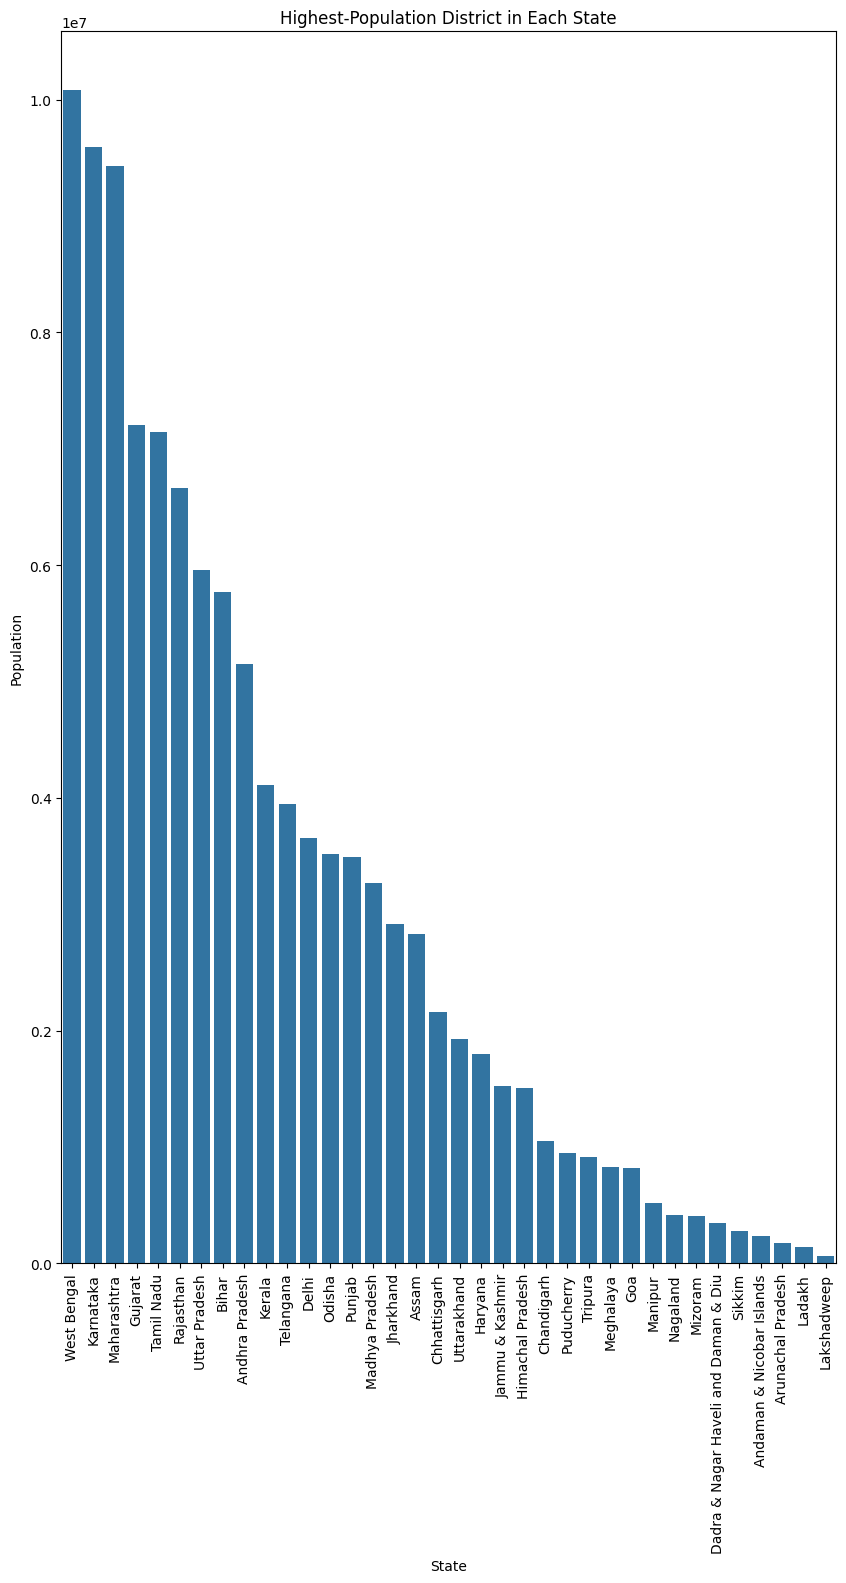

In [46]:
district_maxpop = District_demo.pivot_table(index = ['State', 'District'],
                          values='Population', aggfunc='max').sort_values(by='Population',
                                                                          ascending=False).groupby('State').head(1).reset_index()


print(district_maxpop)

plt.figure(figsize=(10,16))
plt.title('Highest-Population District in Each State')
plt.xlabel('State')
plt.ylabel('Population')
sns.barplot(data=district_maxpop, x='State', y='Population')
plt.xticks(rotation=90)
plt.show()

In [47]:
"""
2.5: Calculate the average transaction value (ATV) for each state

1. Compute the average transaction value for each state. Display the results in a
tabular format.

2. Identify the top 5 states with the highest ATV and the top 5 states with the
lowest ATV. Display the results.
"""

'\n2.5: Calculate the average transaction value (ATV) for each state\n\n1. Compute the average transaction value for each state. Display the results in a\ntabular format.\n\n2. Identify the top 5 states with the highest ATV and the top 5 states with the\nlowest ATV. Display the results.\n'

In [48]:
txn_split.head(2)

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1.845307e+06,439.358921
1,Andaman & Nicobar Islands,2018,1,Peer-to-peer payments,1871,1.213866e+07,6487.790112


In [49]:
#average transaction value (ATV) for each state
txn_split.groupby('State')['ATV (INR)'].mean()

,ATV (INR)
State,
Andaman & Nicobar Islands,2478.973133
Andhra Pradesh,1115.127490
Arunachal Pradesh,1973.155865
Assam,1332.828858
Bihar,1164.766705
Chandigarh,1346.020343
Chhattisgarh,1136.332633
Dadra & Nagar Haveli and Daman & Diu,1106.642239
Delhi,1122.063994


In [50]:
top5_ATV = txn_split.groupby('State')['ATV (INR)'].mean().sort_values(ascending=False).head(5)

top5_ATV

,ATV (INR)
State,
Andaman & Nicobar Islands,2478.973133
Ladakh,2414.441622
Lakshadweep,2103.477400
Mizoram,1997.994730
Arunachal Pradesh,1973.155865


In [51]:
lowest5_ATV = txn_split.groupby('State')['ATV (INR)'].mean().sort_values(ascending=False).tail(5)

lowest5_ATV

,ATV (INR)
State,
Uttar Pradesh,1074.911380
Maharashtra,1072.656215
Madhya Pradesh,994.101576
West Bengal,886.197622
Odisha,852.615941


In [52]:
"""
2.6: Analyze app usage trends

1. Calculate the total number of app opens over the years and quarters for each
state. Display the results in a tabular format.

2. Identify trends in app usage by creating a line plot showing the number of app
opens over time for a selected state.

"""

'\n2.6: Analyze app usage trends\n\n1. Calculate the total number of app opens over the years and quarters for each\nstate. Display the results in a tabular format.\n\n2. Identify trends in app usage by creating a line plot showing the number of app\nopens over time for a selected state.\n\n'

In [53]:
usage_trend  = (
    txn_users.groupby(['State', 'Year', 'Quarter'])['App Opens']
    .sum()
    .reset_index(name='Total App Opens')

)

usage_trend

,State,Year,Quarter,Total App Opens
0,Andaman & Nicobar Islands,2018,1,0
1,Andaman & Nicobar Islands,2018,2,0
2,Andaman & Nicobar Islands,2018,3,0
3,Andaman & Nicobar Islands,2018,4,0
4,Andaman & Nicobar Islands,2019,1,0
...,...,...,...,...
499,West Bengal,2020,2,198589332
500,West Bengal,2020,3,246554831
501,West Bengal,2020,4,291721919
502,West Bengal,2021,1,316832674


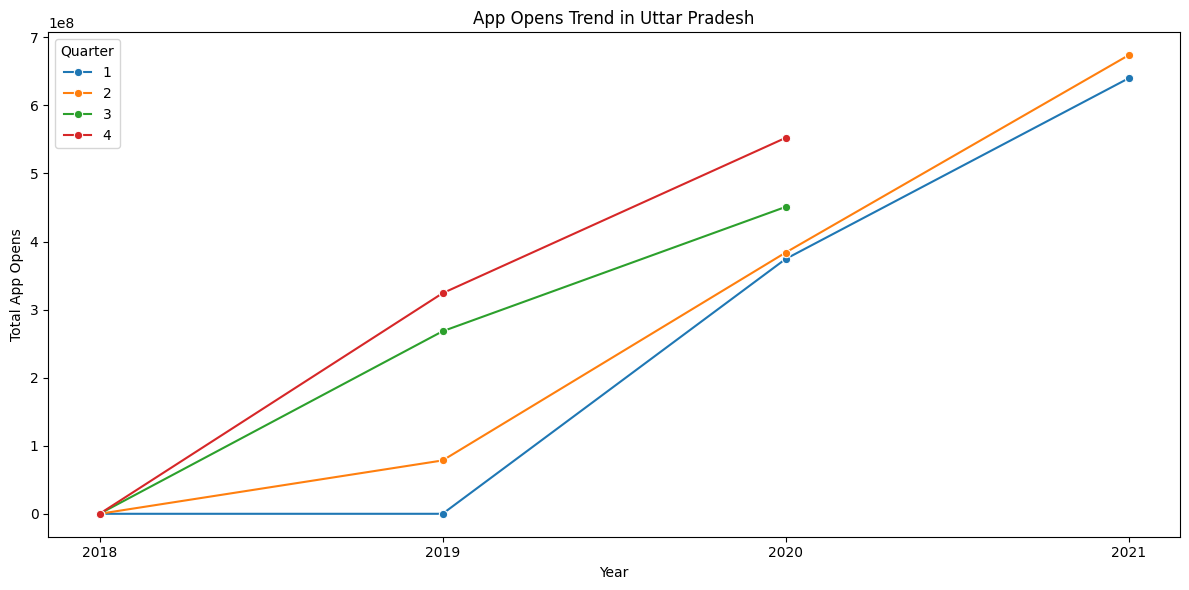

In [54]:
#. Identify trends in app usage by creating a line plot showing the number of app
#opens over time for a selected state

state_data = usage_trend[usage_trend['State'] == 'Uttar Pradesh'].copy()

# Sort by year and quarter
state_data = state_data.sort_values(['Year', 'Quarter'])

# Create the line plot
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=state_data,
    x='Year',
    y='Total App Opens',
    hue='Quarter',
    marker='o',
    palette='tab10'
)

plt.title('App Opens Trend in Uttar Pradesh')
plt.xlabel('Year')
plt.ylabel('Total App Opens')
plt.xticks(sorted(state_data['Year'].unique()))
plt.legend(title='Quarter')
plt.tight_layout()
plt.show()

In [55]:
#2.7: Distribution of transaction types

# Create a bar chart showing the distribution of different transaction types for
# each state for the most recent quarter in the dataset.

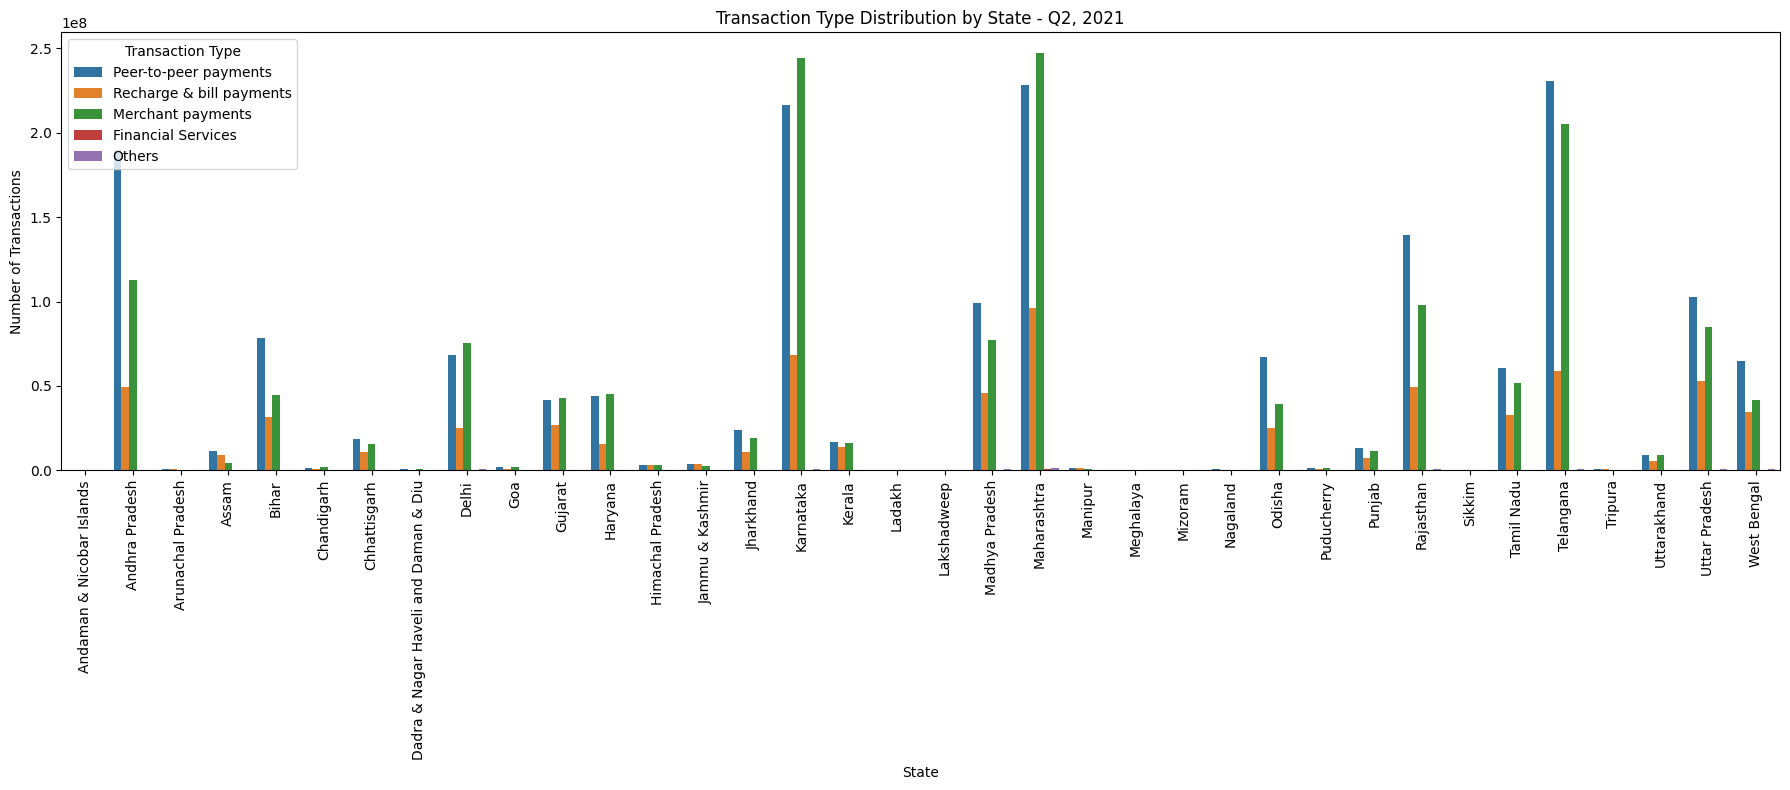

In [56]:
# Step 1: Find the most recent year and quarter
latest_year = txn_split['Year'].max()

latest_quarter = txn_split.loc[
    txn_split['Year'] == latest_year, 'Quarter'
].max()

# Step 2: Filter the most recent quarter
latest_data = txn_split[
    (txn_split['Year'] == latest_year) &
    (txn_split['Quarter'] == latest_quarter)
]

# Step 3: Create a bar chart
plt.figure(figsize=(18, 8))

sns.barplot(
    data=latest_data,
    x='State',
    y='Transactions',
    hue='Transaction Type'
)

plt.title(f'Transaction Type Distribution by State - Q{latest_quarter}, {latest_year}')
plt.xlabel('State')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [57]:
"""
2.8: Find unique mapping between district name and district code

1. Identify the unique mapping between district names and district codes from the
dataset. [hint: you can use drop_duplicates()]

2. Create a CSV file containing the unique district name and district code
mappings.

3. Export the CSV file.

"""

'\n2.8: Find unique mapping between district name and district code\n\n1. Identify the unique mapping between district names and district codes from the\ndataset. [hint: you can use drop_duplicates()]\n\n2. Create a CSV file containing the unique district name and district code\nmappings.\n\n3. Export the CSV file.\n\n'

In [58]:
# Select district name and code
district_mapping = District_users[['District', 'Code']]

# Remove duplicate mappings
district_mapping = district_mapping.drop_duplicates()

# Display results
print(district_mapping)

                        District  Code
0                       Nicobars  AN01
1       North And Middle Andaman  AN02
2                  South Andaman  AN03
42                     Anantapur  AP01
43                      Chittoor  AP02
...                          ...   ...
9944             Purba Bardhaman  WB19
9945             Purba Medinipur  WB20
9946                     Purulia  WB21
9947  South Twenty Four Parganas  WB22
9948              Uttar Dinajpur  WB23

[732 rows x 2 columns]


In [60]:
district_mapping.to_csv(
    'unique_district_name_code_mapping.csv',
    index=False
)

In [ ]:
"""

Task 3: Data Quality Checks
3.1: Ensure data consistency across state and district levels

1. For each state, calculate the total number of transactions, total transaction
amount, and total registered users by summing up the values from the district
level data.

2. Compare the results with the corresponding values at the state level to ensure
they match.

3. Display any discrepancies found between the district-level and state-level data.

"""


In [63]:
district_totals = (
   District_users.groupby(['State', 'Year', 'Quarter'])
    [['Transactions', 'Amount (INR)', 'Registered Users']]
    .sum()
    .reset_index()
)



In [70]:
comparison = txn_users[
    ['State', 'Year', 'Quarter',
     'Transactions', 'Amount (INR)', 'Registered Users']
].merge(
    district_totals,
    on=['State', 'Year', 'Quarter'],
    how='outer',
    suffixes=('_State', '_District'),
    indicator=True
)





# Calculate differences
for col in ['Transactions', 'Amount (INR)', 'Registered Users']:
    comparison[f'{col}_Difference'] = (
        comparison[f'{col}_District'] -
        comparison[f'{col}_State']
    )


discrepancies = comparison[
    (comparison['Transactions_Difference'] != 0) |
    (comparison['Registered Users_Difference'] != 0) |
    (comparison['Amount (INR)_Difference'].abs() > 0.01) |
    (comparison['_merge'] != 'both')
]


discrepancies

,State,Year,Quarter,Transactions_State,Amount (INR)_State,Registered Users_State,Transactions_District,Amount (INR)_District,Registered Users_District,_merge,Transactions_Difference,Amount (INR)_Difference,Registered Users_Difference
279,Madhya Pradesh,2021,2,223314680,4.255008e+11,15940935,223314680,4.255008e+11,15940935,both,0,-0.010437,0
291,Maharashtra,2020,4,407621004,6.221555e+11,34432631,407621004,6.221555e+11,34432631,both,0,0.010620,0


In [ ]:
"""
4.4: Device brand usage ratio

1. Merge the State_DeviceData dataset with the State_Txn and Users dataset.

2. Calculate the ratio of users using each device brand to the total number of
registered users in each state. Display the results in a tabular format.

3. Create a bar chart depicting the device brand usage ratio for each state.

"""

In [72]:
merged_data = pd.merge(
    device_data,
    txn_users,
    on=['State', 'Year', 'Quarter'],
    how='inner',
    suffixes=('_Brand', '_State')
)

# Calculate device brand usage ratio
merged_data['Usage Ratio (%)'] = (
    merged_data['Registered Users_Brand'] /
    merged_data['Registered Users_State']
) * 100

# Display results in tabular format
result = merged_data[
    ['State', 'Year', 'Quarter', 'Brand',
     'Registered Users_Brand', 'Registered Users_State',
     'Usage Ratio (%)']
]

result

,State,Year,Quarter,Brand,Registered Users_Brand,Registered Users_State,Usage Ratio (%)
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,6740,24.703264
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,6740,21.439169
2,Andaman & Nicobar Islands,2018,1,Vivo,982,6740,14.569733
3,Andaman & Nicobar Islands,2018,1,Oppo,501,6740,7.433234
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,6740,4.925816
...,...,...,...,...,...,...,...
5539,West Bengal,2021,2,Lenovo,350841,17979979,1.951287
5540,West Bengal,2021,2,Asus,297579,17979979,1.655058
5541,West Bengal,2021,2,Huawei,272965,17979979,1.518161
5542,West Bengal,2021,2,Apple,201393,17979979,1.120096


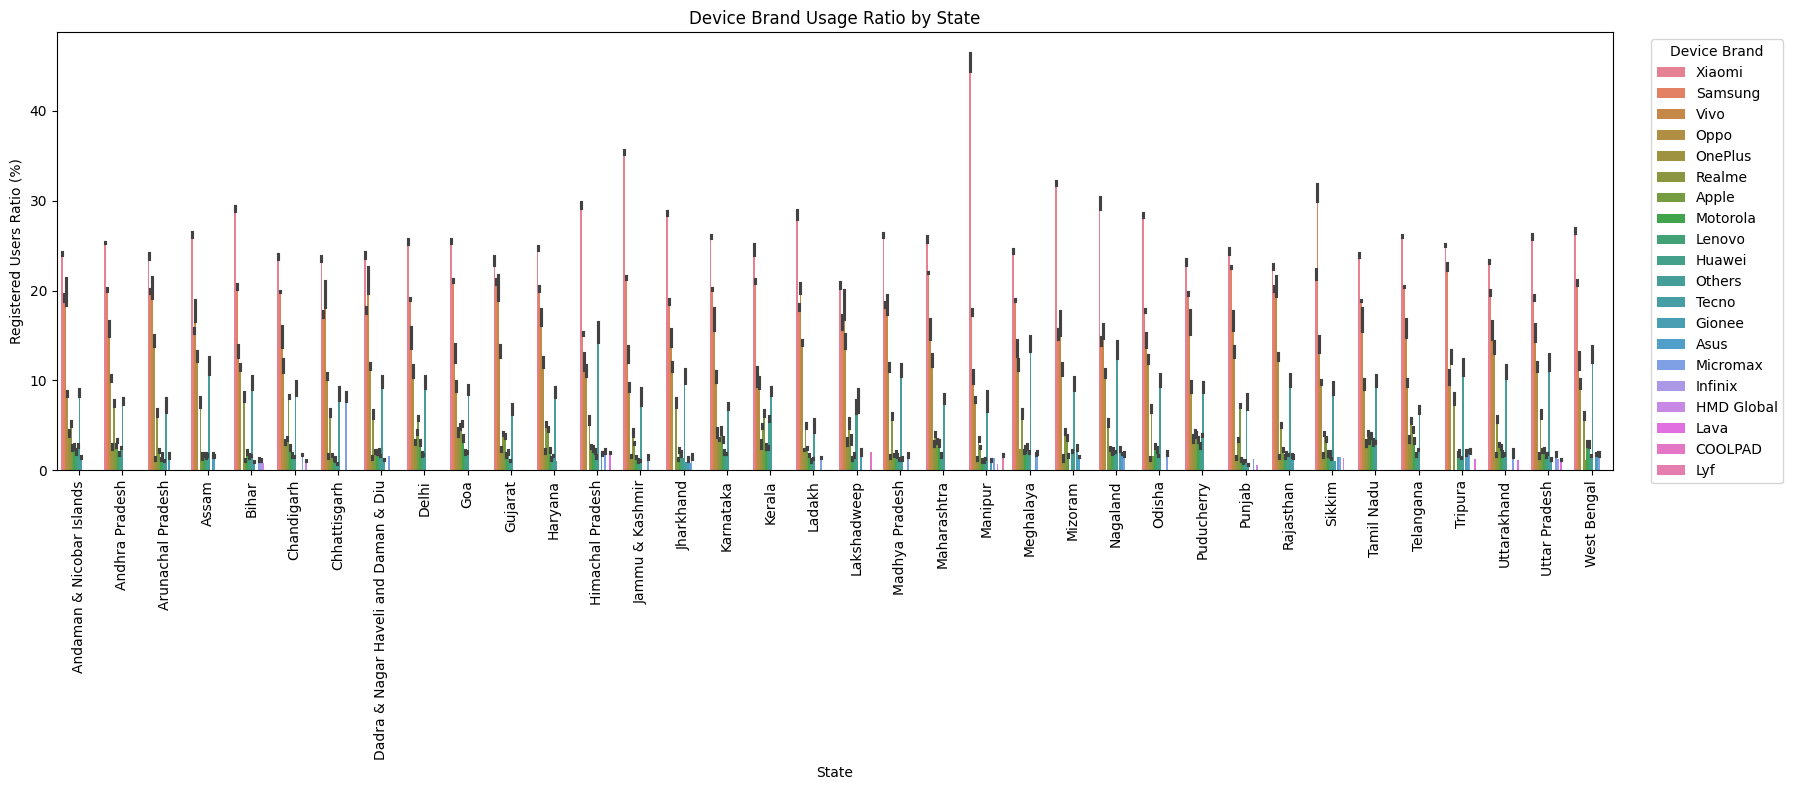

In [73]:
plt.figure(figsize=(18, 8))

sns.barplot(
    data=result,
    x='State',
    y='Usage Ratio (%)',
    hue='Brand'
)

plt.title('Device Brand Usage Ratio by State')
plt.xlabel('State')
plt.ylabel('Registered Users Ratio (%)')
plt.xticks(rotation=90)
plt.legend(title='Device Brand', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [75]:
"""
Task 5: Data Visualization
5.1: Plot the total transactions and amount over time for a selected state

1. Create a line plot showing the total number of transactions and the total
transaction amount over time (years and quarters) for a selected state.

[Hint: you can select any state, maybe your home state or state with max
transactions]
"""

'\nTask 5: Data Visualization\n5.1: Plot the total transactions and amount over time for a selected state\n\n1. Create a line plot showing the total number of transactions and the total\ntransaction amount over time (years and quarters) for a selected state.\n\n[Hint: you can select any state, maybe your home state or state with max\ntransactions]\n'

In [74]:

# Select a state
state_data = txn_split[
    txn_split['State'] == 'Uttar Pradesh'
].copy()

# Aggregate transactions and transaction amount
state_trend = (
    state_data.groupby(['Year', 'Quarter'])
    [['Transactions', 'Amount (INR)']]
    .sum()
    .reset_index()
    .sort_values(['Year', 'Quarter'])
)

# Create chronological labels
state_trend['Period'] = (
    state_trend['Year'].astype(str) + '-Q' +
    state_trend['Quarter'].astype(str)
)

state_trend

,Year,Quarter,Transactions,Amount (INR),Period
0,2018,1,12537805,1.393997e+10,2018-Q1
1,2018,2,17710943,2.572020e+10,2018-Q2
2,2018,3,26515356,3.701211e+10,2018-Q3
3,2018,4,36100767,5.509674e+10,2018-Q4
4,2019,1,57324504,7.652418e+10,2019-Q1
5,2019,2,58883500,9.891752e+10,2019-Q2
6,2019,3,68623959,1.112681e+11,2019-Q3
7,2019,4,86905005,1.455389e+11,2019-Q4
8,2020,1,97239132,1.724164e+11,2020-Q1
9,2020,2,100851965,1.787440e+11,2020-Q2


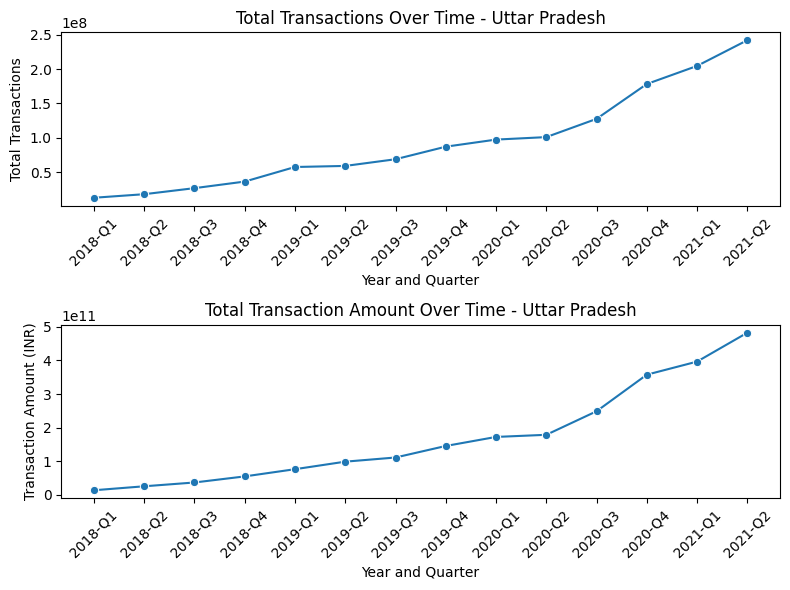

In [82]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6))

# Line plot: total transactions
sns.lineplot(
    data=state_trend,
    x='Period',
    y='Transactions',
    marker='o',
    ax=axes[0]
)
axes[0].set_title('Total Transactions Over Time - Uttar Pradesh')
axes[0].set_xlabel('Year and Quarter')
axes[0].set_ylabel('Total Transactions')
axes[0].tick_params(axis='x', rotation=45)

# Line plot: total transaction amount
sns.lineplot(
    data=state_trend,
    x='Period',
    y='Amount (INR)',
    marker='o',
    ax=axes[1]
)
axes[1].set_title('Total Transaction Amount Over Time - Uttar Pradesh')
axes[1].set_xlabel('Year and Quarter')
axes[1].set_ylabel('Transaction Amount (INR)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

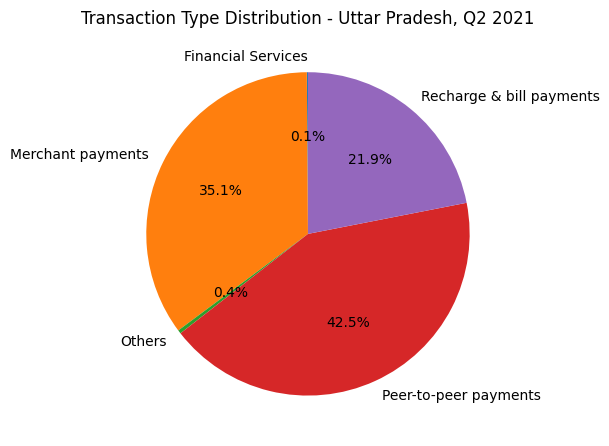

In [80]:
"""
5.2: Create a pie chart showing the distribution of transaction types for a specific
quarter

1. Create a pie chart showing the distribution of different transaction types for a
selected state and quarter.

"""

selected_data = txn_split[
    (txn_split['State'] == 'Uttar Pradesh') &
    (txn_split['Year'] == 2021) &
    (txn_split['Quarter'] == 2)
]

# Calculate total transactions by transaction type
txn_type = selected_data.groupby('Transaction Type')['Transactions'].sum()

# Create pie chart
plt.figure(figsize=(6,8))

plt.pie(
    txn_type,
    labels=txn_type.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Transaction Type Distribution - Uttar Pradesh, Q2 2021')
plt.tight_layout()
plt.show()


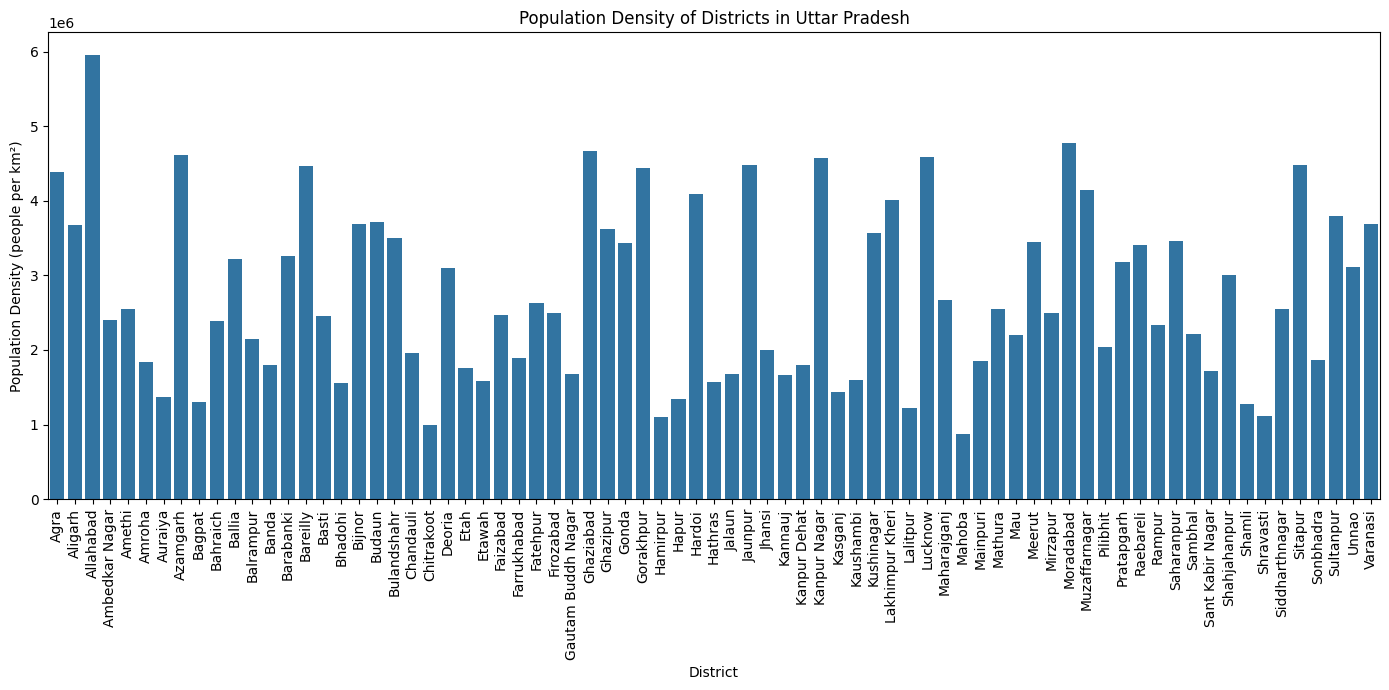

In [88]:
"""
5.3: Visualize the population density of districts in a selected state

1. Create a bar plot showing the population density of districts in a selected state.

"""

state_data = District_demo[
    District_demo['State'] == 'Uttar Pradesh'
]

# Create bar plot
plt.figure(figsize=(14, 7))

sns.barplot(
    data=state_data,
    x='District',
    y='Population',
    errorbar=None
)

plt.title('Population Density of Districts in Uttar Pradesh')
plt.xlabel('District')
plt.ylabel('Population Density (people per km²)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()



In [89]:
"""
Task 6: Insights and Conclusions [Advanced Section]
6.1: Identify any trends or patterns in the transaction data

1. Analyze the transaction data to identify any noticeable trends or patterns.
Summarize your findings. [hint: you can create line graph - at year or quarter
and discuss your findings with interviewer]
"""
trend = (
    txn_split.groupby(['Year', 'Quarter'])[
        ['Transactions', 'Amount (INR)']
    ]
    .sum()
    .reset_index()
    .sort_values(['Year', 'Quarter'])
)

trend['Period'] = (
    trend['Year'].astype(str) + '-Q' +
    trend['Quarter'].astype(str)
)

trend

,Year,Quarter,Transactions,Amount (INR),Period
0,2018,1,134425599,1.718334e+11,2018-Q1
1,2018,2,187365440,3.043742e+11,2018-Q2
2,2018,3,341299764,4.751015e+11,2018-Q3
3,2018,4,417111607,6.717362e+11,2018-Q4
4,2019,1,708992981,9.900214e+11,2019-Q1
5,2019,2,815380896,1.354214e+12,2019-Q2
6,2019,3,1095009675,1.672559e+12,2019-Q3
7,2019,4,1460443663,2.259894e+12,2019-Q4
8,2020,1,1623038046,2.697112e+12,2020-Q1
9,2020,2,1448608890,2.646145e+12,2020-Q2


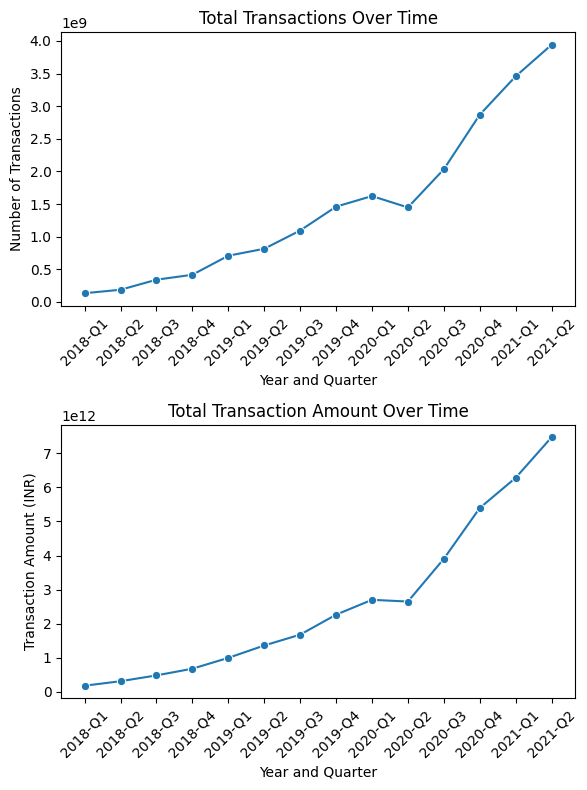

In [95]:
fig, axes = plt.subplots(2, 1, figsize=(6, 8))

# Total number of transactions
sns.lineplot(
    data=trend,
    x='Period',
    y='Transactions',
    marker='o',
    ax=axes[0]
)
axes[0].set_title('Total Transactions Over Time')
axes[0].set_xlabel('Year and Quarter')
axes[0].set_ylabel('Number of Transactions')
axes[0].tick_params(axis='x', rotation=45)

# Total transaction amount
sns.lineplot(
    data=trend,
    x='Period',
    y='Amount (INR)',
    marker='o',
    ax=axes[1]
)
axes[1].set_title('Total Transaction Amount Over Time')
axes[1].set_xlabel('Year and Quarter')
axes[1].set_ylabel('Transaction Amount (INR)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [97]:
"""
6.2: Correlate demographic data with transaction data

1. Find correlations between demographic data (e.g., population density) and
transaction data (e.g., transaction volume). Summarize your findings. [Hint: you
can use corr()]

"""


district_txn = (
    District_users.groupby(['State', 'District'])['Transactions']
    .sum()
    .reset_index()
)

print(District_demo.columns)

district_population = (
    District_demo.groupby(['State', 'District'])['Population']
    .max()
    .reset_index()
)

analysis_df = pd.merge(
    district_population,
    District_users,
    on=['State', 'District'],
    how='inner'
)

correlation = analysis_df[['Population', 'Transactions']].corr()

print(correlation)
print(
    "Correlation between population and transactions:",
    analysis_df['Population'].corr(analysis_df['Transactions'])
)

Index(['State', 'District', 'Headquarters', 'Population', 'Area (sq km)',
       'Density', 'Code', 'Alternate Name'],
      dtype='object')
              Population  Transactions
Population      1.000000      0.359157
Transactions    0.359157      1.000000
Correlation between population and transactions: 0.3591565750346985


In [98]:
"""
6.3: Summarize findings and insights

1. Summarize the key findings and insights from your analysis. Provide actionable
recommendations based on the data. [Hint: type and print your
recommendations and findings in the notebook. This is open ended
"""

findings = [
    "1. Transaction trends: Analyze quarterly transaction counts "
    "and transaction amounts to identify periods of growth or decline.",

    "2. Regional differences: Compare states to identify regions "
    "with high and low transaction volumes.",

    "3. Transaction types: Identify the most common transaction "
    "categories and compare their contribution across states.",

    "4. Device usage: Compare device-brand usage ratios to "
    "understand differences in device adoption across states.",

    "5. Demographic relationship: Use correlation analysis to "
    "evaluate the relationship between district population and "
    "transaction volume. Correlation does not imply causation."
]

recommendations = [
    "1. Focus marketing campaigns on states with low transaction "
    "activity, after accounting for population and market size.",

    "2. Investigate quarters with sudden declines in transactions "
    "to identify possible operational or adoption issues.",

    "3. Improve the user experience for the most widely used "
    "transaction categories and monitor category-level growth.",

    "4. Optimize the app for commonly used device brands and test "
    "compatibility across different devices.",

    "5. Compare transaction volume per capita across districts "
    "to identify underserved markets more fairly.",

    "6. Monitor transaction volume, transaction value, and average "
    "transaction value each quarter to evaluate performance."
]

print("KEY FINDINGS")
print("=" * 50)

for finding in findings:
    print(finding)

print("\nACTIONABLE RECOMMENDATIONS")
print("=" * 50)

for recommendation in recommendations:
    print(recommendation)

KEY FINDINGS
1. Transaction trends: Analyze quarterly transaction counts and transaction amounts to identify periods of growth or decline.
2. Regional differences: Compare states to identify regions with high and low transaction volumes.
3. Transaction types: Identify the most common transaction categories and compare their contribution across states.
4. Device usage: Compare device-brand usage ratios to understand differences in device adoption across states.
5. Demographic relationship: Use correlation analysis to evaluate the relationship between district population and transaction volume. Correlation does not imply causation.

ACTIONABLE RECOMMENDATIONS
1. Focus marketing campaigns on states with low transaction activity, after accounting for population and market size.
2. Investigate quarters with sudden declines in transactions to identify possible operational or adoption issues.
3. Improve the user experience for the most widely used transaction categories and monitor category-l